# Les Jeux de Paris 2024 ont-ils transformé le marché Airbnb parisien ?

À l'été 2024, Paris accueille les Jeux olympiques, puis les Jeux paralympiques. Les épreuves se déroulent dans plusieurs lieux de la capitale et attirent des visiteurs aux besoins d'hébergement variés. Dans les mois qui précèdent, des propriétaires peuvent être tentés de proposer leur logement à la location de courte durée ou d'en modifier le prix. Qu'en observe-t-on dans les données Airbnb ?

Notre étude porte sur l'offre d'annonces et les prix affichés à Paris autour des sites de compétition. Nous cherchons à savoir comment ils évoluent au fil de l'année 2024 et si leur niveau varie avec la distance aux sites olympiques et paralympiques.

Pour cela, nous croisons des relevés d'annonces avec les coordonnées des sites et les contours des arrondissements. Les cartes et les statistiques descriptives permettent d'abord d'explorer les différences entre lieux et entre dates ; une analyse statistique complète ensuite cette exploration.

Les relevés décrivent des annonces à des dates de collecte données. Ils ne nous disent pas directement si un logement a été réservé ni à quel prix il l'a été. Les variations observées peuvent également être liées à la saison ou à d'autres évolutions du marché : elles ne suffisent donc pas à établir un effet causal des Jeux.

## 1. Sources et périmètre

Notre analyse repose sur trois sources :

- **Annonces Airbnb.** Les relevés parisiens proviennent d'Inside Airbnb et sont conservés sur SSP Cloud. Leurs fichiers et leurs dates de collecte sont présentés plus loin.
- **Sites olympiques et paralympiques.** Le ministère chargé des Sports met leurs coordonnées et leurs dates à disposition sur [data.gouv.fr](https://www.data.gouv.fr/api/1/datasets/r/5a0599d1-ad3f-42d1-b64c-204ee19cf520). Le script `sites_competition.py` prépare ces données et documente les corrections de dates ainsi que les sources utilisées pour les justifier.
- **Contours de Paris.** Les limites des 20 arrondissements proviennent de [Paris Data](https://opendata.paris.fr/explore/dataset/arrondissements/). Le fichier `contours_arrondissements.geojson` sert à sélectionner les annonces situées dans Paris et à tracer les cartes.

Nous retenons les annonces dont les coordonnées se trouvent dans Paris intra-muros. Leur position reste approximative : selon [Inside Airbnb](https://insideairbnb.com/data-assumptions/), elle peut être décalée jusqu'à environ 150 mètres par rapport à l'adresse réelle. Cette marge compte lorsque l'on étudie la proximité d'un site.

In [2]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import shape
from shapely.ops import unary_union
from IPython.display import display

from carte_sites_paris import FICHIERS, CONTOURS, SITES, charger_annonces, preparer_population

if not SITES.exists():
    raise FileNotFoundError("Données des sites absentes : exécutez python sites_competition.py puis relancez le notebook.")
from sites_competition import charger_tables_locales, garder_sites_paris

pd.set_option("display.max_columns", 30)
plt.style.use("seaborn-v0_8-whitegrid")

## 2. Sites des Jeux dans Paris

Nous distinguons les sites olympiques des sites paralympiques dans deux tables. Lorsqu'un lieu a servi aux deux événements, il apparaît dans chacune d'elles. Les tableaux indiquent aussi les dates et les coordonnées conservées après préparation des données.

In [3]:
sites_olympiques, sites_paralympiques = charger_tables_locales()
sites_olympiques_paris = garder_sites_paris(sites_olympiques)
sites_paralympiques_paris = garder_sites_paris(sites_paralympiques)
for nom, table in [("Olympiques", sites_olympiques_paris), ("Paralympiques", sites_paralympiques_paris)]:
    print(f"{nom} : {len(table)} lignes, {table['code_site'].nunique()} codes distincts")
    display(table[["code_site", "nom_site", "date_debut", "date_fin", "latitude", "longitude"]])

Olympiques : 19 lignes, 19 codes distincts


,code_site,nom_site,date_debut,date_fin,latitude,longitude
0,BCY,Arena Bercy,2024-07-27,2024-08-11,48.838630,2.378597
1,CDM,Arena Champ de Mars,2024-07-27,2024-08-11,48.853100,2.302520
2,SP1,Arena Paris Sud 1,2024-07-27,2024-08-11,48.832968,2.284007
3,SP4,Arena Paris Sud 4,2024-07-27,2024-08-10,48.830184,2.289033
4,SP6,Arena Paris Sud 6,2024-07-25,2024-08-11,48.829381,2.290865
5,CPL,Arena Porte de la Chapelle,2024-07-27,2024-08-10,48.899729,2.360514
6,GRP,Grand Palais,2024-07-27,2024-08-10,48.866164,2.312547
7,HDV,Hôtel de Ville,2024-08-10,2024-08-11,48.856388,2.352222
8,INV,Invalides,2024-07-25,2024-08-11,48.857048,2.312836
9,LCO,La Concorde,2024-07-27,2024-08-10,48.865704,2.321214


Paralympiques : 12 lignes, 12 codes distincts


,code_site,nom_site,date_debut,date_fin,latitude,longitude
0,BCY,Arena Bercy,2024-08-29,2024-09-08,48.838630,2.378597
1,CDM,Arena Champ de Mars,2024-08-29,2024-09-07,48.853100,2.302520
2,SP1,Arena Paris Sud 1,2024-08-29,2024-09-05,48.832968,2.284007
3,SP4,Arena Paris Sud 4,2024-08-29,2024-09-07,48.830184,2.289033
4,SP6,Arena Paris Sud 6,2024-08-29,2024-09-05,48.829381,2.290865
5,CPL,Arena Porte de la Chapelle,2024-08-29,2024-09-08,48.899729,2.360514
6,GRP,Grand Palais,2024-08-29,2024-09-07,48.866164,2.312547
7,INV,Invalides,2024-08-29,2024-09-08,48.857048,2.312836
8,LCO,La Concorde,2024-08-28,2024-08-28,48.865704,2.321214
9,ALX,Pont Alexandre III,2024-09-02,2024-09-02,48.863700,2.313400


## 3. Nettoyage et qualité des relevés Airbnb

Nous utilisons les relevés distincts disponibles de janvier à décembre 2024 afin de situer l'été des Jeux Olympiques et Paralympiques dans l'évolution de l'année. Les Jeux olympiques se déroulent du 26 juillet au 11 août et les Jeux paralympiques du 28 août au 8 septembre. Les dates de collecte, indiquées par `last_scraped`, couvrent parfois plusieurs jours : un fichier peut donc chevaucher une période de compétition et les jours qui la précèdent ou la suivent.

Le fichier nommé « mars » a été écarté après vérification : il est strictement identique à celui de juin, avec la même empreinte SHA-256. Nous n'avons donc pas de relevé distinct pour mars dans cette série.

Pour chaque fichier, nous gardons une ligne par identifiant, retirons les lignes sans coordonnées et sélectionnons les points situés dans Paris. Nous considérons comme exploitable un prix numérique strictement positif. Les montants sont exprimés en dollars, sans conversion.

In [4]:
mois_etudies = list(FICHIERS)  # Tous les relevés distincts disponibles en 2024.
contours = json.loads(CONTOURS.read_text(encoding="utf-8"))["features"]
if len(contours) != 20:
    raise ValueError("Le fichier doit contenir les 20 arrondissements de Paris.")
paris = unary_union([shape(feature["geometry"]) for feature in contours])

populations, lignes_qualite = {}, []
for mois in mois_etudies:
    print(f"Lecture de {FICHIERS[mois]}…")
    brut = charger_annonces(mois)
    population, controles = preparer_population(brut, paris)
    dates = pd.to_datetime(population["last_scraped"], errors="coerce").dropna()
    nombre = len(population)
    valides = int(population["prix_valide"].sum())
    populations[mois] = population
    lignes_qualite.append({
        "relevé": mois, "collecte_min": dates.min().date() if not dates.empty else None,
        "collecte_max": dates.max().date() if not dates.empty else None,
        "lignes_brutes": controles["lignes"], "sans_identifiant": controles["sans_id"],
        "doublons": controles["doublons"], "sans_coordonnées": controles["sans_coord"],
        "hors_Paris": controles["hors_paris"], "annonces_Paris": nombre,
        "prix_valides": valides, "prix_invalides_ou_manquants": nombre - valides,
        "part_prix_valides_%": round(100 * valides / nombre, 1) if nombre else float("nan"),
    })
qualite = pd.DataFrame(lignes_qualite).set_index("relevé")
display(qualite)

Lecture de etiennealpy/données paris/listing_13_janvier_2024…
Chargement des annonces : etiennealpy/données paris/listing_13_janvier_2024 ...
Lecture de etiennealpy/données paris/listing_14_fevrier_2024…
Chargement des annonces : etiennealpy/données paris/listing_14_fevrier_2024 ...
Lecture de etiennealpy/données paris/listing_17_avril_2024.csv…
Chargement des annonces : etiennealpy/données paris/listing_17_avril_2024.csv ...
Lecture de etiennealpy/données paris/listing_11_mai_2024.csv…
Chargement des annonces : etiennealpy/données paris/listing_11_mai_2024.csv ...
Lecture de etiennealpy/données paris/listing_10_juin_2024…
Chargement des annonces : etiennealpy/données paris/listing_10_juin_2024 ...
Lecture de etiennealpy/données paris/listing_14_juillet_2024.csv…
Chargement des annonces : etiennealpy/données paris/listing_14_juillet_2024.csv ...
Lecture de etiennealpy/données paris/listing_09_aout_2024.csv…
Chargement des annonces : etiennealpy/données paris/listing_09_aout_2024.csv ..

,collecte_min,collecte_max,lignes_brutes,sans_identifiant,doublons,sans_coordonnées,hors_Paris,annonces_Paris,prix_valides,prix_invalides_ou_manquants,part_prix_valides_%
relevé,,,,,,,,,,,
janvier,2024-01-14,2024-01-30,76938,0,0,0,0,76938,55672,21266,72.4
fevrier,2024-02-14,2024-02-22,80545,0,0,0,0,80545,56396,24149,70.0
avril,2024-04-17,2024-04-22,88548,0,0,0,0,88548,66388,22160,75.0
mai,2024-05-11,2024-05-14,92665,0,0,0,0,92665,70934,21731,76.5
juin,2024-06-11,2024-06-14,95885,0,0,0,0,95885,74579,21306,77.8
juillet,2024-07-14,2024-07-28,98810,0,0,0,0,98810,77010,21800,77.9
aout,2024-08-09,2024-08-15,98736,0,0,0,0,98736,74401,24335,75.4
septembre,2024-09-06,2024-09-13,95461,0,0,0,0,95461,64230,31231,67.3
octobre,2024-10-07,2024-10-11,93275,0,0,0,0,93275,61611,31664,66.1


### Effectifs et prix renseignés

Le nombre d'annonces localisées à Paris progresse au fil des relevés disponibles : il passe de **76 938 en janvier à 98 810 en juillet**, soit environ 28,4 % de plus. Il diminue ensuite pour atteindre **91 031 en décembre**, environ 7,9 % en dessous de juillet. La série ne comporte toutefois pas de relevé distinct pour mars. Ces chiffres décrivent les annonces présentes lors des collectes ; ils ne permettent pas de compter les logements loués.

Autour des Jeux, l'effectif passe de **95 885 en juin à 98 810 en juillet**. Il reste proche de ce niveau en août (98 736), puis recule en septembre (95 461). La hausse commence donc avant l'été. Elle peut refléter l'anticipation des Jeux, mais aussi des variations saisonnières ou des différences dans les collectes ; ces résultats seuls ne permettent pas de départager ces explications.

Les prix ne sont pas disponibles pour toutes les annonces. Leur part exploitable est de **77,8 % en juin, 77,9 % en juillet, 75,4 % en août et 67,3 % en septembre**. Pour ce dernier relevé, 31 231 annonces, soit 32,7 %, n'ont pas de prix exploitable. La proportion tombe ensuite autour des deux tiers en octobre, novembre et décembre. Si les annonces sans prix diffèrent des autres, les médianes calculées sur les seuls prix renseignés peuvent donner une image partielle du marché immobilier.


### Que nous apprend la disponibilité ?

La variable `availability_30` compte les nuits affichées comme disponibles pendant les **30 jours suivant la collecte**. Le tableau présente, pour chaque relevé, le nombre de valeurs utilisables, leur médiane et la part des annonces qui n'affichent aucune nuit disponible sur cette période.

Une nuit indisponible n'est pas forcément louée : l'hôte peut aussi la bloquer, et certaines règles du calendrier peuvent empêcher une réservation. Cette variable ne donne donc pas un taux de réservation réel. De plus, la période de 30 jours change avec la date de collecte ; elle ne correspond pas exactement aux dates des épreuves. Ces limites sont expliquées par [Inside Airbnb](https://insideairbnb.com/data-assumptions/) et par [Airbnb](https://www.airbnb.com/help/article/3612).

In [5]:
lignes_disponibilite = []
for mois, population in populations.items():
    valeurs = pd.to_numeric(population['availability_30'], errors='coerce')
    valides = valeurs.loc[valeurs.between(0, 30)]
    lignes_disponibilite.append({
        'relevé': mois, 'annonces à Paris': len(population),
        'disponibilités valides': len(valides),
        'disponibilités manquantes ou invalides': len(population) - len(valides),
        'nuits disponibles médianes': valides.median(),
        'part avec 0 nuit disponible (%)': 100 * valides.eq(0).mean() if len(valides) else float('nan'),
    })
disponibilites = pd.DataFrame(lignes_disponibilite).set_index('relevé')
display(disponibilites.round(1))

,annonces à Paris,disponibilités valides,disponibilités manquantes ou invalides,nuits disponibles médianes,part avec 0 nuit disponible (%)
relevé,,,,,
janvier,76938,76938,0,0.0,54.9
fevrier,80545,80545,0,0.0,53.9
avril,88548,88548,0,1.0,49.3
mai,92665,92665,0,0.0,50.6
juin,95885,95885,0,4.0,42.1
juillet,98810,98810,0,15.0,25.0
aout,98736,98736,0,11.0,29.9
septembre,95461,95461,0,1.0,47.7
octobre,93275,93275,0,2.0,47.7


Entre juin et juillet, la disponibilité affichée augmente dans nos relevés : la médiane passe de **4 à 15 nuits** sur les 30 jours suivants. Elle est ensuite de 11 nuits en août, puis de 1 en septembre. Sur les mêmes relevés, la part d'annonces sans aucune nuit disponible est respectivement de **42,1 %, 25,0 %, 29,9 % et 47,7 %**.

Ces résultats décrivent l'état des calendriers à quatre moments différents. Ils ne disent pas combien de nuits ont été réservées : une disponibilité faible peut aussi venir de nuits bloquées. Les fenêtres observées n'étant pas les mêmes d'un mois à l'autre, on ne peut pas non plus attribuer directement leurs écarts aux Jeux.

## 4. Prix affichés et types de logement

Pour décrire les prix renseignés, nous utilisons la médiane : la moitié des valeurs exploitables se situe en dessous et l'autre moitié au-dessus. Elle est moins sensible que la moyenne à quelques prix très élevés. Nous regardons aussi les effectifs par type de logement, car la proportion de logements entiers ou de chambres peut varier d'un relevé à l'autre. Les prix sont exprimés en dollars, sans conversion.

In [6]:
synthese, types = [], []
for mois, population in populations.items():
    valides = population.loc[population["prix_valide"]]
    synthese.append({"relevé": mois, "annonces": len(population), "prix exploitables": len(valides),
                     "prix médian ($)": valides["prix"].median()})
    groupes = population.assign(type_logement=population["room_type"].fillna("Non renseigné"))
    for categorie, groupe in groupes.groupby("type_logement"):
        prix = groupe.loc[groupe["prix_valide"], "prix"]
        types.append({"relevé": mois, "type de logement": categorie, "annonces": len(groupe),
                      "prix exploitables": len(prix), "prix manquants ou invalides": len(groupe)-len(prix),
                      "prix médian ($)": prix.median()})
synthese = pd.DataFrame(synthese).set_index("relevé")
par_type = pd.DataFrame(types)
display(synthese.round(2))
display(par_type.round(2))

,annonces,prix exploitables,prix médian ($)
relevé,,,
janvier,76938,55672,148.0
fevrier,80545,56396,150.0
avril,88548,66388,160.0
mai,92665,70934,163.5
juin,95885,74579,164.0
juillet,98810,77010,159.0
aout,98736,74401,170.0
septembre,95461,64230,155.0
octobre,93275,61611,160.0


,relevé,type de logement,annonces,prix exploitables,prix manquants ou invalides,prix médian ($)
0,janvier,Entire home/apt,67346,49166,18180,150.0
1,janvier,Hotel room,824,810,14,265.0
2,janvier,Private room,8302,5371,2931,100.0
3,janvier,Shared room,466,325,141,50.0
4,fevrier,Entire home/apt,70872,50610,20262,152.0
5,fevrier,Hotel room,808,548,260,189.0
6,fevrier,Private room,8386,4906,3480,96.0
7,fevrier,Shared room,479,332,147,54.0
8,avril,Entire home/apt,78711,60190,18521,166.0
9,avril,Hotel room,788,544,244,237.0


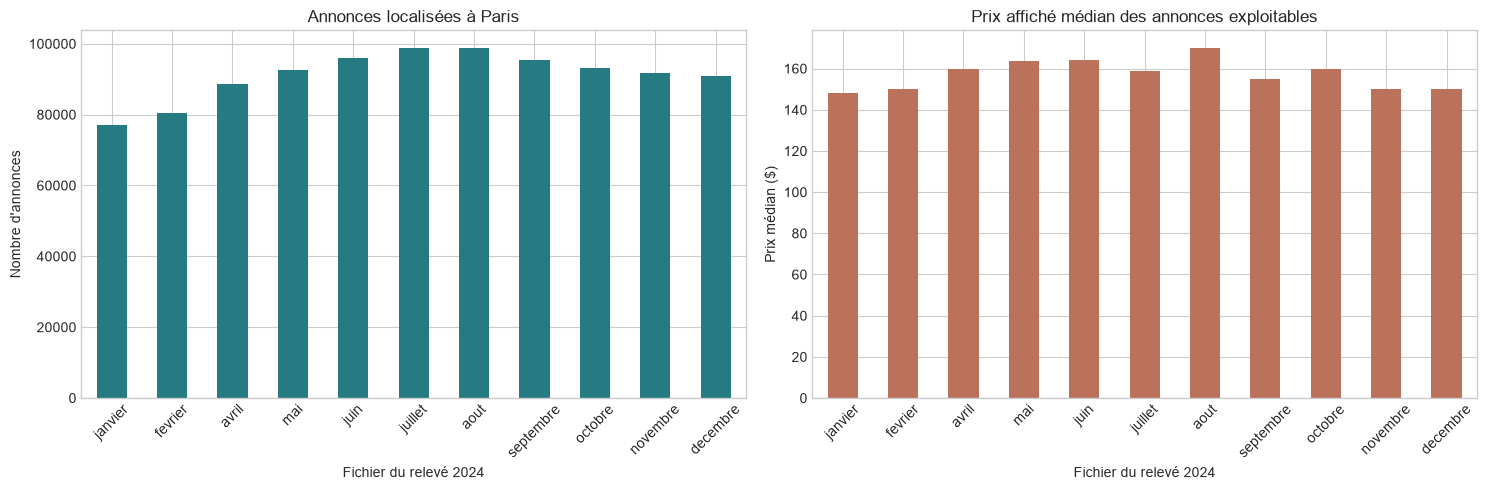

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
synthese["annonces"].plot.bar(ax=axes[0], color="#267b83", rot=45)
axes[0].set(title="Annonces localisées à Paris", xlabel="Fichier du relevé 2024", ylabel="Nombre d'annonces")
synthese["prix médian ($)"].plot.bar(ax=axes[1], color="#bc725a", rot=45)
axes[1].set(title="Prix affiché médian des annonces exploitables", xlabel="Fichier du relevé 2024", ylabel="Prix médian ($)")
fig.tight_layout()
plt.show()

Les graphiques permettent de comparer les relevés, mais leur lecture doit tenir compte de la part de prix manquants présentée plus haut. Une variation de la médiane peut aussi refléter un changement dans les annonces observées, notamment dans la part de logements entiers et de chambres. Ces chiffres ne décrivent pas les prix effectivement payés.

## 5. Cartographie et suite du projet

Le script `carte_sites_paris.py` représente les prix médians par maille et situe les lieux de compétition olympiques et paralympiques. Les cartes partagent la même échelle de couleurs. Une maille reste neutre lorsqu'elle contient moins de cinq prix exploitables : cela ne signifie pas qu'aucun logement ne s'y trouve.

La suite de l'analyse devra examiner les prix selon la distance aux sites, en indiquant le nombre d'annonces dans chaque tranche. Les données disponibles pour 2023 et 2025 et les résultats de la régression d'Othmane restent à intégrer après vérification de leur comparabilité.

## 6. Limites et conclusion provisoire

Les premiers résultats portent sur des prix affichés et sur les annonces présentes dans chaque relevé. Ils ne mesurent ni les réservations ni les sommes payées. Les prix manquants, la localisation approximative et les changements possibles dans la composition des annonces invitent aussi à la prudence.

L'analyse de la distance et la comparaison avec d'autres années permettront de préciser ces observations. La conclusion sera rédigée une fois ces résultats examinés collectivement.